It is highly recommended to use a powerful **GPU**, you can use it for free uploading this notebook to [Google Colab](https://colab.research.google.com/notebooks/intro.ipynb).
<table align="center">
 <td align="center"><a target="_blank" href="https://colab.research.google.com/github/ezponda/intro_deep_learning/blob/main/class/CNN/Visualizing_What_CNNs_Learn.ipynb">
        <img src="https://colab.research.google.com/img/colab_favicon_256px.png"  width="50" height="50" style="padding-bottom:5px;" />Run in Google Colab</a></td>
  <td align="center"><a target="_blank" href="https://github.com/ezponda/intro_deep_learning/blob/main/class/CNN/Visualizing_What_CNNs_Learn.ipynb">
        <img src="https://github.githubassets.com/images/modules/logos_page/GitHub-Mark.png"  width="50" height="50" style="padding-bottom:5px;" />View Source on GitHub</a></td>
</table>


**Table of Contents**

1. [Introduction](#introduction)
2. [Accessing Layers and Weights in TensorFlow](#accessing_layers)
3. [Visualizing Layer Outputs](#visualizing_outputs)
4. [Methods for Interpretation](#interpretation)
    * 4.1 [Gradient-weighted Class Activation Mapping (Grad-CAM)](#gradcam)
    * 4.2 [Integrated Gradients](#integrated_gradients)
5. [Visualizing Filters with Gradient Ascent](#gradient_ascent)

<a id='introduction'></a>
# Introduction

Convolutional Neural Networks (CNNs) have been successful in solving complex machine learning problems, particularly in image recognition tasks. Although they are highly effective, they are also often criticized as being black boxes since the learned representations are hard to interpret. Fortunately, we have several visualization techniques to shed some light on what's happening inside these networks.

<a id='accessing_layers'></a>
# Accessing Layers and Weights in TensorFlow


To visualize what CNNs learn, we first need to access the internal components of our CNN model, including its layers and weights. In TensorFlow, the layers of a model can be accessed using the .layers attribute and weights can be accessed using the .get_weights() method.

Here is a simple example of how you can access these components:

In [1]:
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input

import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np

# Load the VGG16 model pre-trained on ImageNet
model_VGG16 = VGG16()

model_VGG16.summary()

553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 24s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1000)           │     4,097,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,357,544 (527.79 MB)

 Trainable params: 138,357,544 (527.79 MB)

 Non-trainable params: 0 (0.00 B)

In [2]:
# Accessing layers
for layer in model_VGG16.layers:
    print("Layer Name : ", layer.name)

Layer Name :  input_layer
Layer Name :  block1_conv1
Layer Name :  block1_conv2
Layer Name :  block1_pool
Layer Name :  block2_conv1
Layer Name :  block2_conv2
Layer Name :  block2_pool
Layer Name :  block3_conv1
Layer Name :  block3_conv2
Layer Name :  block3_conv3
Layer Name :  block3_pool
Layer Name :  block4_conv1
Layer Name :  block4_conv2
Layer Name :  block4_conv3
Layer Name :  block4_pool
Layer Name :  block5_conv1
Layer Name :  block5_conv2
Layer Name :  block5_conv3
Layer Name :  block5_pool
Layer Name :  flatten
Layer Name :  fc1
Layer Name :  fc2
Layer Name :  predictions


In [3]:
# Accessing weights of a specific layer
W, b = model_VGG16.layers[1].get_weights()
W.shape, b.shape

((3, 3, 3, 64), (64,))

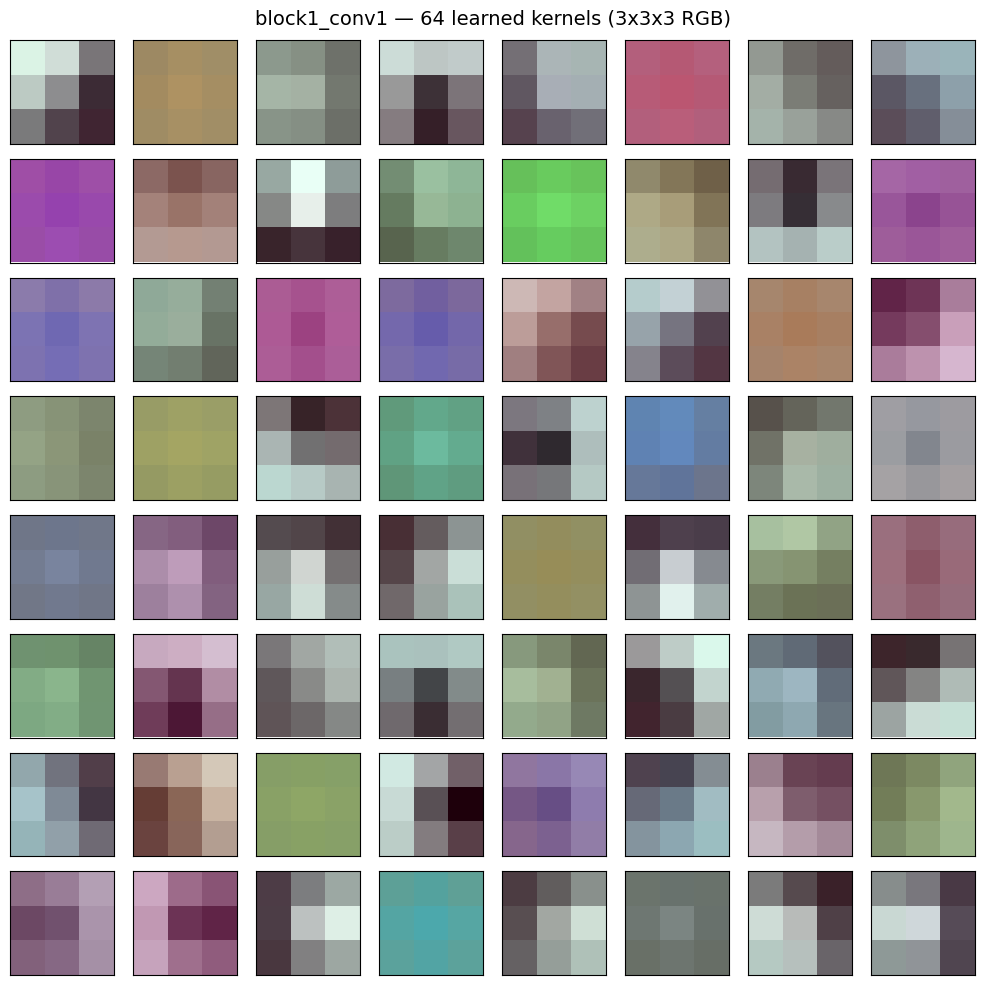

In [4]:
# The weights of the first conv layer are 64 filters of shape 3x3x3, so we can
# display each of them directly as a small RGB patch (edge / color detectors).
W, b = model_VGG16.layers[1].get_weights()

# Normalize weights to [0, 1] for display
W_norm = (W - W.min()) / (W.max() - W.min())

fig, axes = plt.subplots(8, 8, figsize=(10, 10))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(W_norm[:, :, :, i])
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle('block1_conv1 — 64 learned kernels (3x3x3 RGB)', fontsize=14)
plt.tight_layout()
plt.show()

<a id='visualizing_outputs'></a>
## 3. Visualizing Layer Outputs

One of the key insights about CNNs is that they learn a **hierarchy of features**: early layers detect simple patterns (edges, colors), middle layers combine them into textures and shapes, and deeper layers recognize complex semantic concepts.

Let's visualize what different layers "see" when processing an image.

9156/9156 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


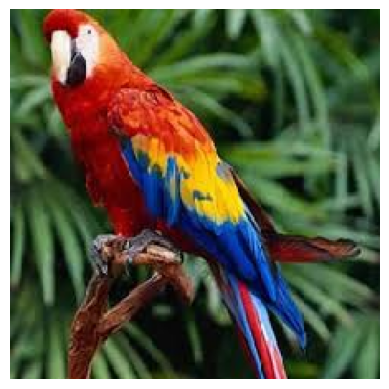

In [5]:
def read_image(image_path, target_size=None, color_mode='rgb'):
    image = tf.keras.utils.load_img(image_path,
                                    target_size=target_size,
                                    color_mode=color_mode)
    image = tf.keras.utils.img_to_array(image)
    image = image.astype(np.uint8)
    return image


url = 'https://raw.githubusercontent.com/ezponda/intro_deep_learning/main/images/bird.jpg'
image_path = tf.keras.utils.get_file("bird.jpg", url)
image = read_image(image_path, target_size=(224, 224))
img = np.expand_dims(image, axis=0)
plt.imshow(image)
plt.axis('off')
plt.show()

In [6]:
from tensorflow.keras.models import Model

# Get the symbolic outputs of each "key" layer (we gave them unique names).
outputs_dict = {layer.name: layer.output for layer in model_VGG16.layers}

# Set up a model that returns the activation values for every layer in
# VGG16 (as a dict).
feature_extractor = Model(inputs=model_VGG16.inputs, outputs=outputs_dict)

In [7]:
## Get the features of the image
features = feature_extractor(img)
print(features.keys())

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


dict_keys(['input_layer', 'block1_conv1', 'block1_conv2', 'block1_pool', 'block2_conv1', 'block2_conv2', 'block2_pool', 'block3_conv1', 'block3_conv2', 'block3_conv3', 'block3_pool', 'block4_conv1', 'block4_conv2', 'block4_conv3', 'block4_pool', 'block5_conv1', 'block5_conv2', 'block5_conv3', 'block5_pool', 'flatten', 'fc1', 'fc2', 'predictions'])


block1_conv1 feature maps shape: (1, 224, 224, 64)


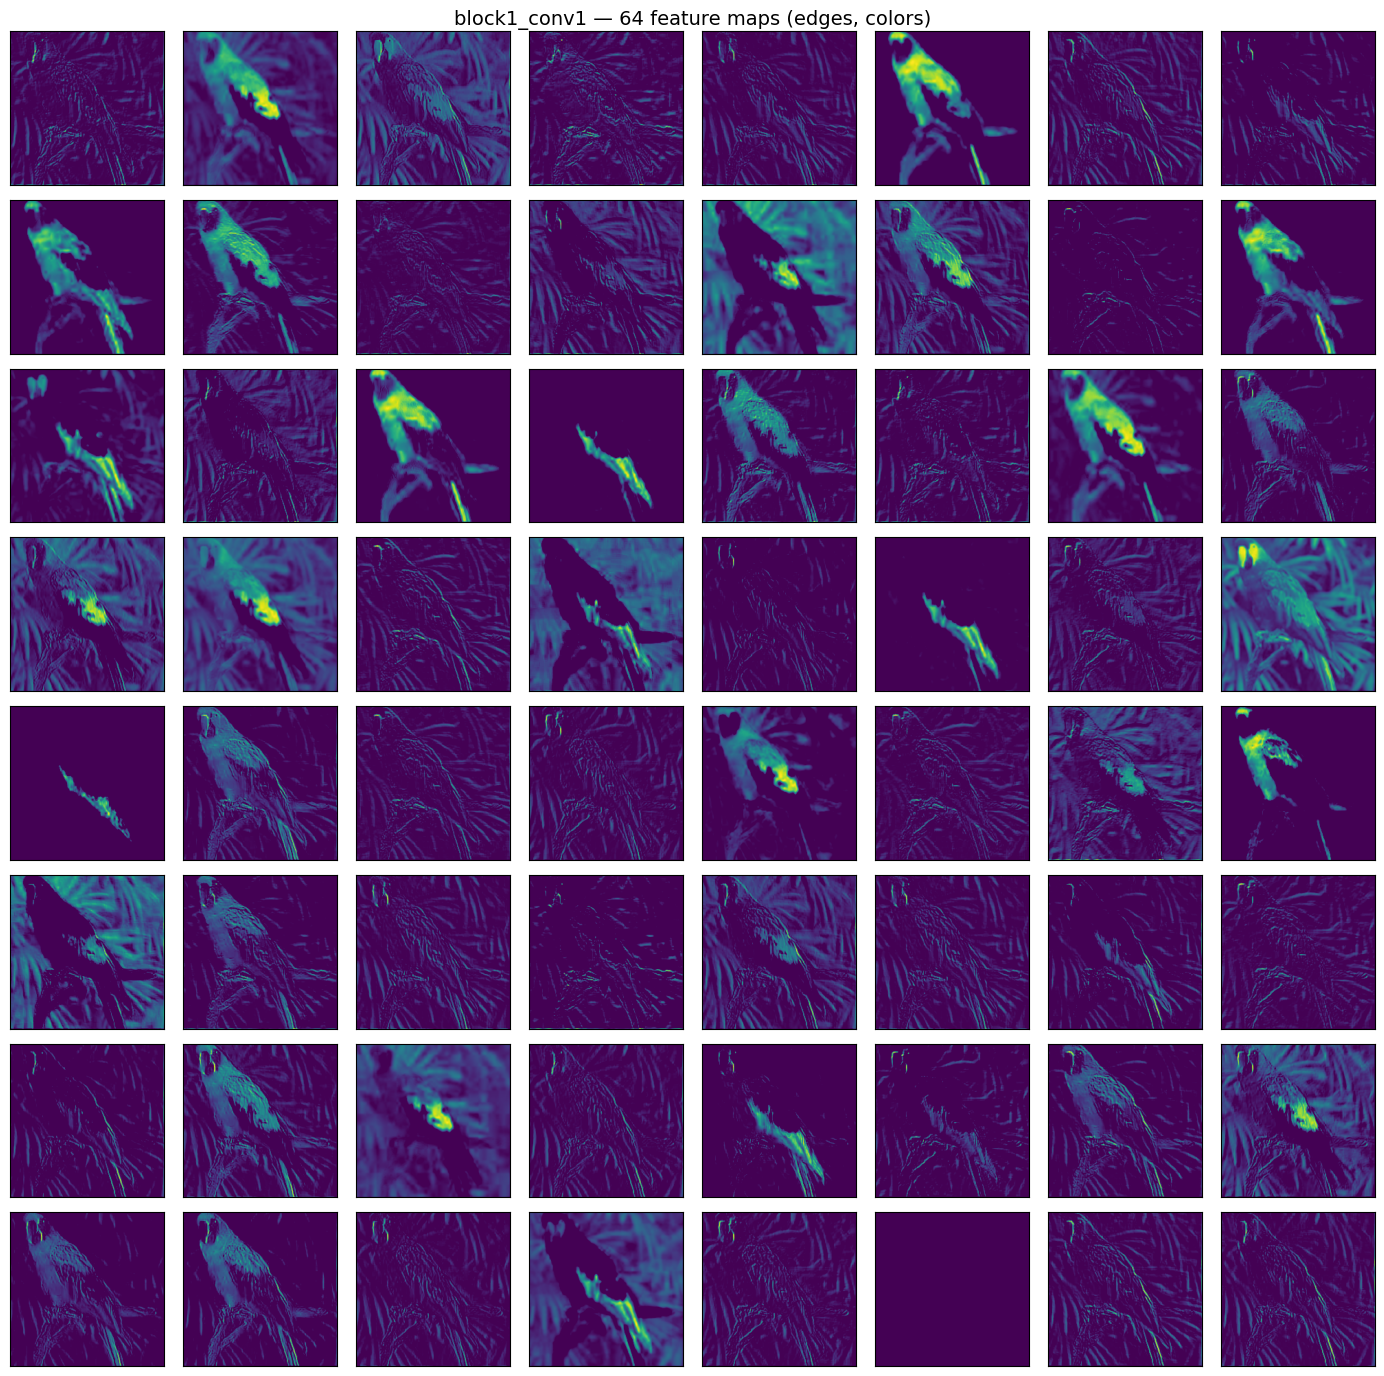

In [8]:
# Feature maps of the first convolutional layer (64 filters)
feature_maps = features['block1_conv1']
print('block1_conv1 feature maps shape:', feature_maps.shape)

fig, axes = plt.subplots(8, 8, figsize=(14, 14))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(feature_maps[0, :, :, i], cmap='viridis')
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle('block1_conv1 — 64 feature maps (edges, colors)', fontsize=14)
plt.tight_layout()
plt.show()

### Feature hierarchy: from low-level to high-level

As we go deeper into the network, the feature maps become more abstract:
- **Early layers** (block1): detect edges, colors and simple textures.
- **Middle layers** (block3): detect more complex patterns, shapes and parts of objects.
- **Deep layers** (block5): detect high-level semantic concepts (entire objects, faces, scenes). The spatial resolution is much lower, but each pixel encodes rich information.

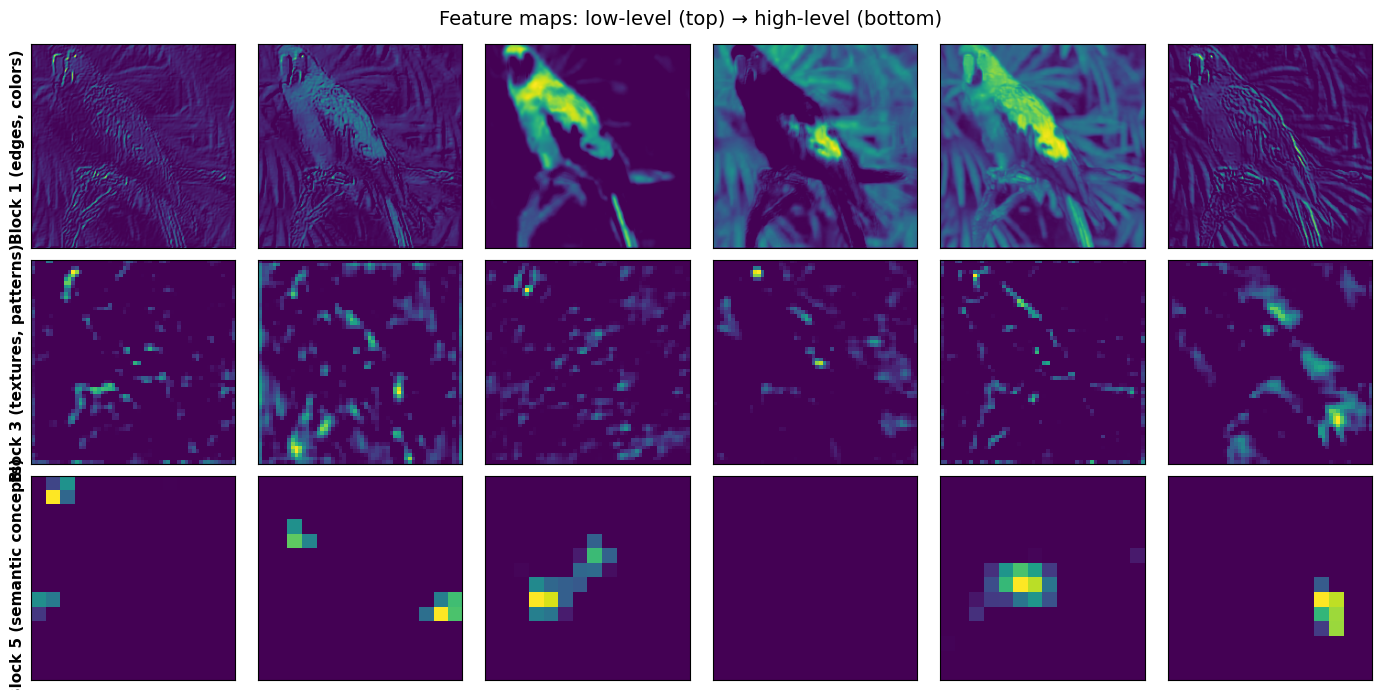

In [9]:
# Compare feature maps from early, middle and deep layers
layers_to_show = ['block1_conv2', 'block3_conv3', 'block5_conv3']
layer_labels = ['Block 1 (edges, colors)', 'Block 3 (textures, patterns)', 'Block 5 (semantic concepts)']
n_filters = 6

fig, axes = plt.subplots(len(layers_to_show), n_filters, figsize=(14, 7))

for row, (layer_name, label) in enumerate(zip(layers_to_show, layer_labels)):
    fmaps = features[layer_name]
    for col in range(n_filters):
        axes[row, col].imshow(fmaps[0, :, :, col], cmap='viridis')
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
    axes[row, 0].set_ylabel(label, fontsize=11, fontweight='bold')

plt.suptitle('Feature maps: low-level (top) → high-level (bottom)', fontsize=14)
plt.tight_layout()
plt.show()

<a id='interpretation'></a>
# Methods for Interpretation

There are several methods for interpreting the results from CNNs. We will look into two popular ones: Grad-CAM and Saliency Maps.

<a id='imagenet'></a>
## imagenet

ImageNet is a large dataset of over 14 million labeled images spanning 20,000+ categories. The images were collected from the internet and labeled by human annotators using Amazon's Mechanical Turk crowdsourcing tool.

For the purpose of this tutorial, the ImageNet dataset is particularly relevant because the model we're using (VGG16) was trained on ImageNet. The dataset consists of 1000 different classes, and thus, the model is capable of recognizing 1000 different types of objects.

The ImageNet class index file we download is a dictionary that maps the class indices, which are the output of the model's prediction, to human-readable labels. When we visualize the Grad-CAM heatmaps, we use these labels to understand what the model is recognizing. This is why we need the ImageNet class index in this tutorial.


In [10]:
import json
import requests

# URL of the ImageNet class index
url = 'https://s3.amazonaws.com/deep-learning-models/image-models/imagenet_class_index.json'

# Send a HTTP request to the URL
response = requests.get(url)
print(response.status_code)
# If the request is successful, the status code will be 200
if response.status_code == 200:
    # Get the content of the response
    content = response.content

    # Save the json content into a dictionary
    CLASS_INDEX = json.loads(content)

    # Save the dictionary into a local file so you don't have to download it every time
    with open('imagenet_class_index.json', 'w') as f:
        json.dump(CLASS_INDEX, f)

    # Let's test it:
    print(CLASS_INDEX[str(282)])  # it should print ['n02123045', 'tabby'] (a kind of cat)

else:
    print("Failed to download the file. Status code:", response.status_code)


200
['n02123159', 'tiger_cat']


In [11]:
# Transform CLASS_INDEX to class_name:index
class2index = {value[1]: int(key) for key, value in CLASS_INDEX.items()}

# Let's test it:
class2index

{'tench': 0,
 'goldfish': 1,
 'great_white_shark': 2,
 'tiger_shark': 3,
 'hammerhead': 4,
 'electric_ray': 5,
 'stingray': 6,
 'cock': 7,
 'hen': 8,
 'ostrich': 9,
 'brambling': 10,
 'goldfinch': 11,
 'house_finch': 12,
 'junco': 13,
 'indigo_bunting': 14,
 'robin': 15,
 'bulbul': 16,
 'jay': 17,
 'magpie': 18,
 'chickadee': 19,
 'water_ouzel': 20,
 'kite': 21,
 'bald_eagle': 22,
 'vulture': 23,
 'great_grey_owl': 24,
 'European_fire_salamander': 25,
 'common_newt': 26,
 'eft': 27,
 'spotted_salamander': 28,
 'axolotl': 29,
 'bullfrog': 30,
 'tree_frog': 31,
 'tailed_frog': 32,
 'loggerhead': 33,
 'leatherback_turtle': 34,
 'mud_turtle': 35,
 'terrapin': 36,
 'box_turtle': 37,
 'banded_gecko': 38,
 'common_iguana': 39,
 'American_chameleon': 40,
 'whiptail': 41,
 'agama': 42,
 'frilled_lizard': 43,
 'alligator_lizard': 44,
 'Gila_monster': 45,
 'green_lizard': 46,
 'African_chameleon': 47,
 'Komodo_dragon': 48,
 'African_crocodile': 49,
 'American_alligator': 50,
 'triceratops': 51,
 


<a id='gradcam'></a>
## 4.1 Gradient-weighted Class Activation Mapping (Grad-CAM)

[Grad-CAM](https://arxiv.org/abs/1610.02391) answers the question: *which parts of the image made the model choose this class?* It produces a coarse heatmap over the image highlighting the regions that mattered.

**The core idea.** The last convolutional layer holds many feature maps (channels). Each channel is a *detector* for some pattern — an "ear", a "stripe texture", an "eye" — and it keeps a rough map of **where** that pattern appears. Grad-CAM figures out **which detectors matter for the class** (using gradients) and then paints **where those detectors fired** (using the feature maps).

**Step by step — what each step does and why:**

1. **Forward pass → class score $y^c$.** Run the image through the network and read the score of the target class (before softmax).
   *Why:* this is the single number we want to explain — "how strongly does the model vote for *shark*?"

2. **Keep the last conv feature maps $A^k$.** For VGG16 that is a 14×14×512 tensor: 512 detectors, each with a 14×14 map of where it responded.
   *Why:* it is the deepest layer that still knows **where** things are; after it, the spatial information is flattened away.

3. **Gradient of the score w.r.t. each feature map, $\dfrac{\partial y^c}{\partial A^k}$.**
   *Why:* the gradient says *"if this detector were a bit more active, would the class score go up?"* A positive gradient means the detector is **evidence for** the class. This is how we discover which detectors matter, without anyone labelling them.

4. **Average the gradient of each map over width and height → a weight $\alpha^c_k$.**
   *Why:* we do not care *where* a detector is important, only *how* important it is overall. Averaging turns each detector's gradient map into a single **importance weight** for this class.

5. **Weighted sum of the maps, then ReLU: $L = ReLU(\sum_k \alpha^c_k A^k)$.**
   *Why:* we add up every detector's *where-map*, each scaled by its importance, so the result lights up wherever the **important** detectors fired. The **ReLU** drops negative contributions, keeping only what pushes *towards* the class (not against it).

In symbols, the importance weights and the final map are:

$$\alpha^c_k = \frac{1}{Z} \sum_i \sum_j \frac{\partial y^c}{\partial A^k_{ij}} \qquad\qquad L^c_{Grad\text{-}CAM} = ReLU\Big(\sum_k \alpha^c_k A^k\Big)$$

We will use the [tf-keras-vis](https://keisen.github.io/tf-keras-vis-docs/) library. Two notes about the code below:

- We use **Grad-CAM++**, an improved variant that gives sharper, better-localized maps (especially when the object appears several times).
- `ReplaceToLinear()` swaps the final softmax for a linear activation, so the gradients come from the raw class score — with softmax they would saturate and weaken the map.

Note the gradient here flows back only to the **last conv layer, not to the pixels** — that is why Grad-CAM gives coarse *regions* (14×14, upscaled to the image) rather than fine detail. Warm colors = regions that pushed the score up the most. For pixel-level attribution, see Integrated Gradients next.

In [12]:
!pip install -q "tf-keras-vis>=0.8.7"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.5/52.5 kB 1.9 MB/s eta 0:00:00


670776/670776 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


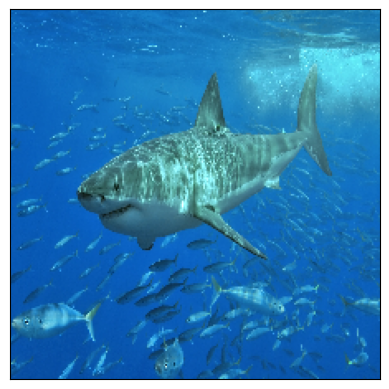

In [14]:
# great_white_shark image
url = 'https://raw.githubusercontent.com/ezponda/intro_deep_learning/main/images/white_shark.jpg'
image_path = tf.keras.utils.get_file("great_white_shark2.jpg", url)
image = read_image(image_path, target_size=(224, 224))
img = np.expand_dims(image, axis=0)
plt.imshow(image, cmap='viridis')
plt.xticks([])
plt.yticks([])
plt.show()

In [15]:
X = preprocess_input(img)

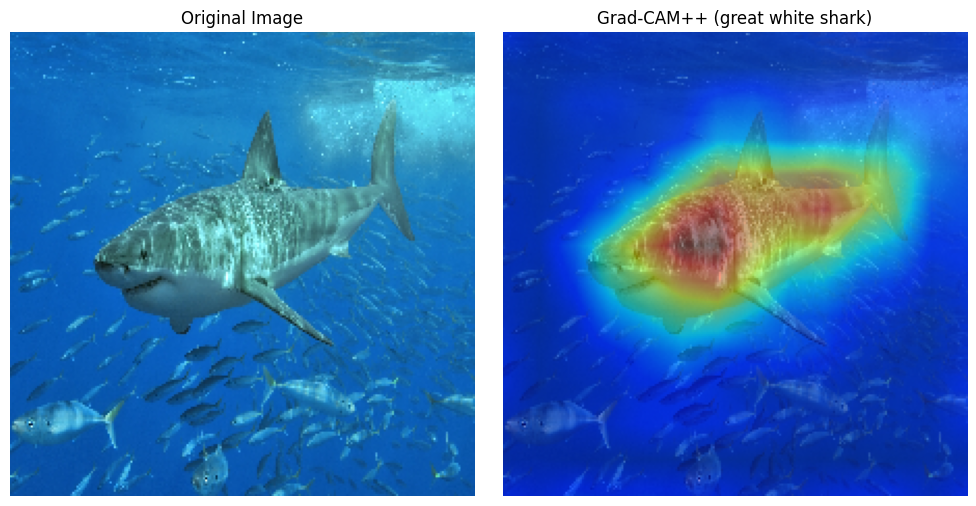

In [16]:
from matplotlib import cm
from tf_keras_vis.gradcam_plus_plus import GradcamPlusPlus
from tf_keras_vis.utils.model_modifiers import ReplaceToLinear
from tf_keras_vis.utils.scores import CategoricalScore

categorical_index = class2index['great_white_shark']

# Create GradCAM++ object
gradcam = GradcamPlusPlus(model_VGG16,
                          model_modifier=ReplaceToLinear(),
                          clone=True)

# Generate heatmap with GradCAM++
cam = gradcam(CategoricalScore(categorical_index), X,
              penultimate_layer=-1)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(image)
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(image)
heatmap = np.uint8(cm.jet(cam[0])[..., :3] * 255)
axes[1].imshow(heatmap, cmap='jet', alpha=0.5)
axes[1].set_title('Grad-CAM++ (great white shark)')
axes[1].axis('off')

plt.tight_layout()
plt.show()

<a id='integrated_gradients'></a>
## 4.2 Integrated Gradients

Grad-CAM stopped at the last conv layer, so it only gave us *regions*. **Integrated Gradients** goes all the way down to the **pixels**: it scores how much each individual pixel contributed to the prediction.

**The intuition, step by step:**

- The gradient of the class score with respect to a pixel means: *"if I brighten this pixel a little, how much does the 'shark' score change?"* Large magnitude → influential pixel. That alone is a plain [saliency map](https://arxiv.org/abs/1312.6034).
- **Problem:** at the real image the network is usually **saturated** — the shark is already fully recognized, so nudging any single pixel barely moves the score and the gradient is ≈ 0, *even for pixels that clearly matter*.
- **Fix ([Integrated Gradients](https://arxiv.org/abs/1703.01365)):** start from a **neutral baseline** (a blank image) and walk in a straight line towards the real image, **adding up the gradients along the way**. Early on the path the object is still forming, so the gradients there are informative; integrating them recovers each pixel's true contribution.
- Finally we multiply by (pixel − baseline), so each pixel is credited only for how much it actually differs from the baseline.

$$IG_i(x) = (x_i - x'_i) \times \int_{\alpha=0}^{1} \frac{\partial F(x' + \alpha (x - x'))}{\partial x_i}\, d\alpha$$

where $x$ is the image, $x'$ the baseline and $F$ the model. We approximate the integral with a Riemann sum over a few dozen steps.

Two details matter for a clean result: we take the gradient of the **pre-softmax logit** (softmax saturates the gradients even more), and we clip the attribution at a high percentile for contrast. The whole thing only needs `tf.GradientTape` — no extra library.

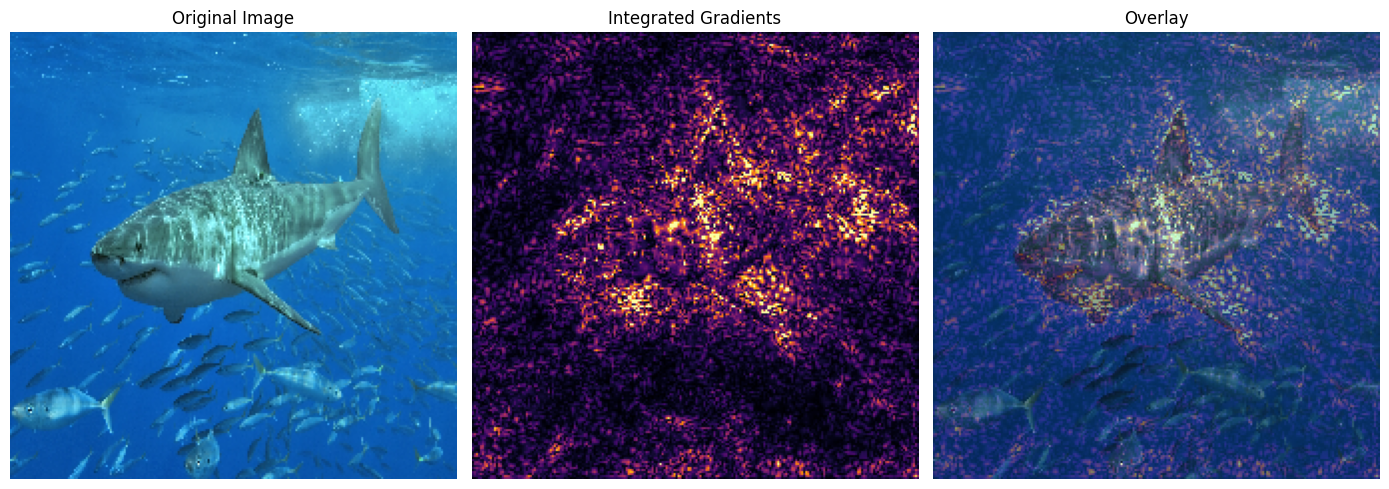

In [17]:
# Integrated Gradients works best on the pre-softmax logits: the softmax
# saturates the gradients and adds noise. We build a version of VGG16 without
# the final softmax (same weights, only the last activation changes).
logit_model = tf.keras.applications.VGG16(weights='imagenet', classifier_activation=None)


def integrated_gradients(model, x, class_index, steps=50):
    baseline = tf.zeros_like(x)  # neutral baseline
    alphas = tf.linspace(0.0, 1.0, steps + 1)[:, tf.newaxis, tf.newaxis, tf.newaxis]
    interpolated = baseline + alphas * (x - baseline)  # (steps+1, H, W, C)

    with tf.GradientTape() as tape:
        tape.watch(interpolated)
        scores = model(interpolated)[:, class_index]
    grads = tape.gradient(scores, interpolated)

    # Trapezoidal approximation of the path integral
    avg_grads = tf.reduce_mean((grads[:-1] + grads[1:]) / 2.0, axis=0)
    return ((x - baseline)[0] * avg_grads).numpy()


ig = integrated_gradients(logit_model, X, categorical_index, steps=50)

# Aggregate across color channels, then clip at the 99th percentile for contrast
attribution = np.sum(np.abs(ig), axis=-1)
attribution = np.clip(attribution / np.percentile(attribution, 99), 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].imshow(image)
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(attribution, cmap='inferno')
axes[1].set_title('Integrated Gradients')
axes[1].axis('off')

axes[2].imshow(image)
axes[2].imshow(attribution, cmap='inferno', alpha=0.5)
axes[2].set_title('Overlay')
axes[2].axis('off')

plt.tight_layout()
plt.show()

<a id='gradient_ascent'></a>
# 5. Visualizing Filters with Gradient Ascent

The previous methods explain a **given image**. This one is different: it takes **no input image at all**. We start from random noise and run **gradient ascent** in pixel space — nudging the pixels to *maximize* the activation of one filter. The image we end up with is the filter's **preferred input**: the pattern it is most tuned to detect.

**How it works:** at each step we ask *"how should each pixel change to make this filter fire more?"* (that is the gradient), take a small step in that direction, and repeat. After ~30 steps the random noise organizes itself into the pattern the filter is looking for. It is the same machinery as before (a single layer's output + `tf.GradientTape`), but now the gradient flows back to the **input pixels** instead of the weights.

Reading the result across depth reveals the **feature hierarchy**:
- **Early layers** prefer simple colors and edges.
- **Middle layers** prefer textures (weaves, dots, grids).
- **Deep layers** prefer elaborate, object-part-like patterns.

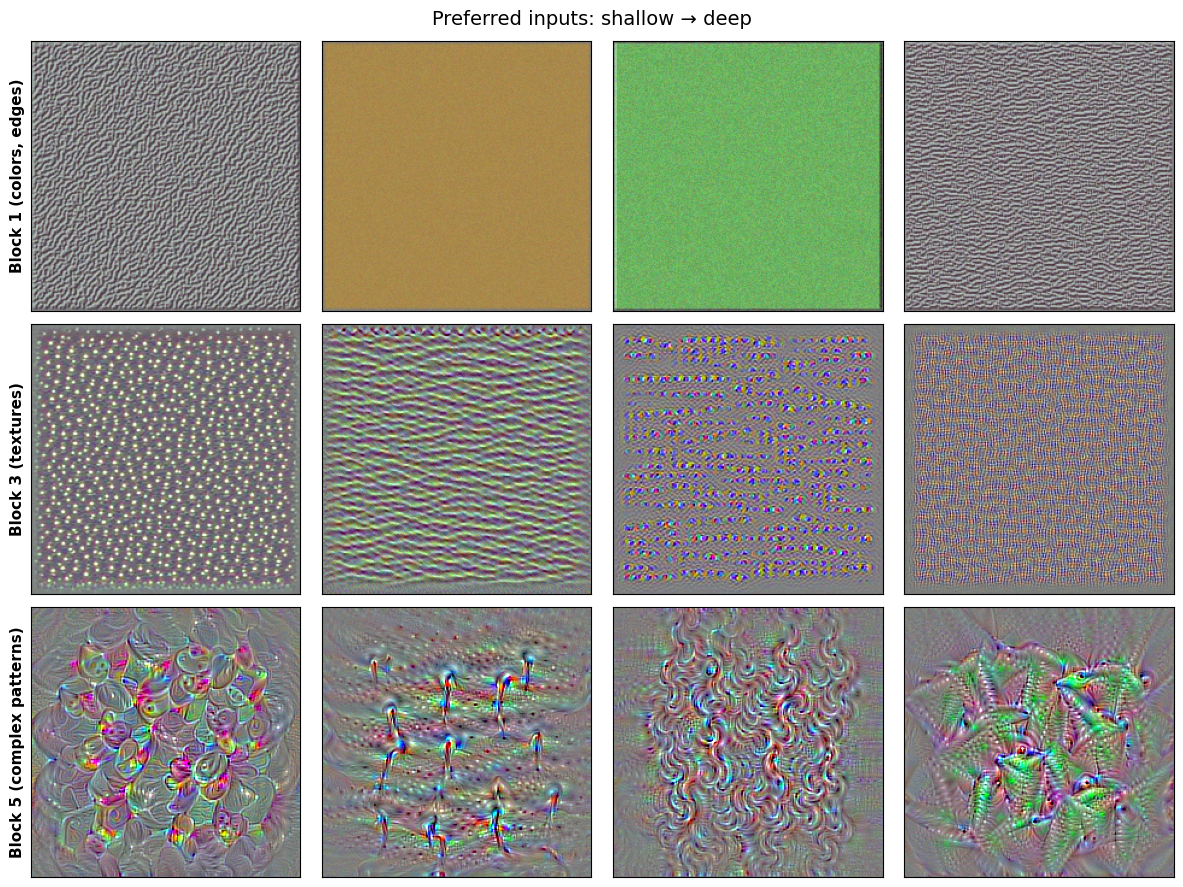

In [18]:
from tensorflow.keras.models import Model


def visualize_filter(layer_name, filter_index, size=224, iterations=30, learning_rate=2.0):
    # Build a model that outputs the activations of the target layer.
    # VGG16 has a fixed 224x224 input, so we keep that size.
    layer = model_VGG16.get_layer(name=layer_name)
    extractor = Model(inputs=model_VGG16.inputs, outputs=layer.output)

    # Start from a gray image with a little random noise
    img = tf.random.uniform((1, size, size, 3)) * 20 + 128.0
    for _ in range(iterations):
        with tf.GradientTape() as tape:
            tape.watch(img)
            activation = extractor(img)
            # Ignore border pixels to avoid edge artifacts
            loss = tf.reduce_mean(activation[:, 2:-2, 2:-2, filter_index])
        grads = tape.gradient(loss, img)
        # Normalize the gradient by its RMS so the ascent takes even, smooth steps
        grads /= tf.sqrt(tf.reduce_mean(tf.square(grads))) + 1e-5
        img = img + learning_rate * grads

    # Normalize the result into a displayable RGB image
    img = img[0].numpy()
    img -= img.mean()
    img /= img.std() + 1e-5
    img = np.clip(img * 0.15 + 0.5, 0, 1)
    return (img * 255).astype('uint8')


# Preferred inputs from a shallow, a middle and a deep layer.
# (Some deep filters barely activate from random noise, so we pick ones that respond well.)
rows = [
    ('block1_conv1', [0, 1, 2, 3], 'Block 1 (colors, edges)'),
    ('block3_conv1', [0, 1, 2, 3], 'Block 3 (textures)'),
    ('block5_conv1', [3, 7, 8, 17], 'Block 5 (complex patterns)'),
]

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for row, (layer_name, filters, label) in enumerate(rows):
    for col, fi in enumerate(filters):
        axes[row, col].imshow(visualize_filter(layer_name, fi))
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
    axes[row, 0].set_ylabel(label, fontsize=11, fontweight='bold')
plt.suptitle('Preferred inputs: shallow → deep', fontsize=14)
plt.tight_layout()
plt.show()